In [ ]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
manual_ann = """
[ A / I ]: "[El euro]_A //
representa la respuesta europea para conseguir el objetivo de un mayor nivel de empleo y bienestar de [nuestros ciudadanos]_I".
[ A / (B) ]: "[El euro]_A //
es la mejor base para crear empleo" { , [insistió]f_B }.
[ B / IM ]: [Rato]_B //
aprovechó la reunión para entregar a [la Comisión Europea]_I [el programa de estabilidad español]_M  { , que incluye el objetivo de eliminar totalmente el déficit público en el 2002 y situar el nivel de renta español en el 85% de la media comunitaria } .
[ AB / AT(B) ]: Ayer mismo, en [el primer día del euro]_A, [Rato]_B //
destacó las capacidades de [la moneda única europea]_A como instrumento para avanzar en la solución de problemas "como es el empleo, la calidad de vida, la calidad de los servicios públicos, la sanidad, las pensiones y, en definitiva, [la prosperidad de los españoles]_T" { , [dijo]f_B }.
[ (C)D / A ]: { En su última actuación como presidente del Consejo de Economía, [el ministro austriaco, Rudolf Edlinger,]f_C resaltó el jueves que } "[el momento]_D //
es idóneo para la introducción del [euro]_A", con un crecimiento sostenido, las cuentas públicas saneadas y una inflación muy baja.
[ A / IE ]: [El euro]_A { , incluso antes de ser creado, } //
protegió a la [UE]_I durante el año pasado de [la grave crisis financiera internacional]_E y
[ I / I ]: [la]_I //
convirtió en [un polo de estabilidad]_I { , señaló [Edlinger]f } .
[ (F) /  ]: { [Alemania]f_F recordó que } ahora //
debe cumplirse el pacto de estabilidad y reclamó que se respete el compromiso de evitar la competencia desleal en la fiscalidad.
[ G / I ]: [Portugal]_G //
aprovechó para defender la solidaridad y la cohesión dentro de [la UE]_I, { amenazados por el plan de los países ricos de recortar las ayudas } .
[ A / I(Q) ]: "[Un euro estable y fuerte]_A //
necesita [una UE fuerte]_I" { , afirmó [el ministro portugués, António de Sousa]f_Q } .
[ A / I ]: [La divisa única]_A //
evidencia la disparidad de poder adquisitivo y renta entre [países]_I.
[ A / R ]: [Una única moneda con la que manejarse en un amplio espacio geográfico sin fronteras físicas]_A //
es la mejor herramienta para la transparencia de [precios]_R.
[  / R ]: No //
cuesta igual un mismo [producto]_R en Barcelona que en Murcia o en Pontevedra.
[  / U ]: //
Hay factores como la renta per cápita que pesan y que condicionan las [políticas de precios]_U.
[ R / FSA ]: Por ejemplo, [la hamburguesa simple de McDonald's]_R { , que en Barcelona cuesta 170 pesetas -1,02 euros-, } //
en [Berlín]_F supera [las 212 pesetas]_S o [1,28 euros]_A.
[ S / H ]: En [pesetas]_S //
se ve [la diferencia]_H de forma bien transparente:
[ F / HR ]: En [Berlín]_F //
cuesta [un 25% más]_H hincarle el diente a [uno de los productos más estandarizados que existen]_R.
[ A / H ]: En [euros]_A, //
parece que existen [menos diferencias]_H, pero
[ A / S ]: { Hay que tener en cuenta que } cada [cent]_A - - fracción en la que se divide el euro - - //
son [1, 66 pesetas]_S.
[ H / S ]: { Ello significa que } [los 26 cents de diferencia entre las dos hamburguesas (la de Barcelona y la de Berlín)]_H //
, equivalen a [más de 43 pesetas]_S { , es decir, el mismo 25% que si se hace la comparación en pesetas }.
[ I /  ]: { Es cuestión de } [recuperar]_I //
la memoria y
[ I / T ]: [recordar]_I //
la etapa en la que era habitual en [España]_T contar céntimos y otras fracciones de la unidad de cuenta.
[ J / UI ]: [Tal circunstancia]_J //
deberán tenerla en cuenta las empresas de gran consumo en [sus políticas de precios]_U en [Eurolandia]_I.
[  /  ]: //
No bastará con hacer la conversión.
[ R /  ]: [El precio de un diario traducido a euros, 0,75 cents,]_R //
resulta más operativo que 0,748 { , aunque el redondeo excesivo también sea peligroso } .
[ L /  ]: [Las circunstancias de cada país]_L //
pesan.
[ T / F ]: [Un español]_T //
tiene alrededor del 60% de la renta de un [alemán]_F.
[ F / HR ]: { No es tan raro, por tanto que } [el berlinés]_F //
pague [más del doble]_H que el barcelonés por [un billete de metro]_R, entre [otros servicios y productos]_R.
[ (N)R / TR ]: Según [el estudio realizado]f_N, con la ayuda de corresponsales del diario Eliseo Oliveras (Bruselas), Montserrat Capdevila(París) y Gonzalo Cáceres(Berlín), [todos los productos]_R //
son más baratos en [España]_T, con la excepción del [modelo de Peugeot 306 más simple]_R { , que tiene el precio comparable en euros más bajo en Bruselas } .
[ F / R ]: [Alemania]_F, por su parte, el país con más renta de los analizados, //
es más cara para todo, excepto para [el paquete de Winston]_R.
[ R / R ]: Incluso [la bajada de bandera del taxi]_R { , que oscila entre el equivalente a 2, 05 y 3, 07 euros, en función de la carrera, } //
es la más cara de [todas]_R.
[  / I ]: //
Una de las servidumbres de vivir en [la tercera potencia económica mundial]_I, { ahora integrada en la segunda, } Eurolandia.
"""

In [ ]:
def parse_side(side_text, side_type):
    """
    Parsea cabeceras de lado temático/remático y soporta ambas notaciones:
      '(A)B' -> B es la mención principal y A es su fuente
      'B(A)' -> B es la mención principal y A es su fuente
      'DA'    -> D y A son menciones normales
    """
    items = []
    clean = side_text.replace(" ", "")

    # 1) (A)B   2) B(A)   3) A
    token_pattern = re.compile(r'(?:\(([A-Z])\)([A-Z])|([A-Z])\(([A-Z])\)|([A-Z]))')

    for m in token_pattern.finditer(clean):
        if m.group(1) and m.group(2):
            source_id, main_id = m.group(1), m.group(2)
        elif m.group(3) and m.group(4):
            main_id, source_id = m.group(3), m.group(4)
        else:
            main_id, source_id = m.group(5), None

        items.append({
            'concept_letter': main_id,
            'texto': None,
            'tipo': side_type,
            'es_fuente': False,
            'cadena_fuente': ''
        })

        if source_id:
            items.append({
                'concept_letter': source_id,
                'texto': None,
                'tipo': side_type,
                'es_fuente': True,
                'cadena_fuente': f'{main_id}({source_id})'
            })

    return items


def extract_body_mentions(fragment, side_type, modal=False):
    """
    Extrae menciones del cuerpo y admite tanto:
      [texto]_A      -> mención normal
      [texto]f_A     -> mención marcada como fuente
      [texto]_(A)    -> mención modal
      [texto]f_(A)   -> mención modal marcada como fuente
    """
    items = []

    if modal:
        patterns = [r'\[([^]]+?)\](f)?_\(([A-Z])\)']
    else:
        patterns = [r'\[([^]]+?)\](f)?_([A-Z])']

    for pattern in patterns:
        for texto, flag_fuente, letra in re.findall(pattern, fragment):
            conceptos_dict.setdefault(letra, None)
            if conceptos_dict[letra] is None:
                conceptos_dict[letra] = texto

            items.append({
                'concept_letter': letra,
                'texto': texto,
                'tipo': side_type,
                'es_fuente': bool(flag_fuente),
                'cadena_fuente': ''
            })

    return items


bloques = re.findall(r'\[\s*(.*?)\s*\]:\s*(.+?\n.+?)\n(?=\[|$)', manual_ann, re.S)

conceptos_dict = {}   # letra -> texto representativo
menciones_list = []
oraciones = []

for cabecera, oracion_ann in bloques:

    if '/' in cabecera:
        cab_tema, cab_rema = [x.strip() for x in cabecera.split('/', 1)]
    else:
        cab_tema, cab_rema = cabecera.strip(), ''

    menciones_list_ora = []

    # Mentions declared in the sentence header, including sources in parentheses
    for item in parse_side(cab_tema, 'T') + parse_side(cab_rema, 'R'):
        conceptos_dict.setdefault(item['concept_letter'], None)
        menciones_list_ora.append(item)

    # Theme mentions in the sentence body
    tema = oracion_ann.split("//")[0]
    menciones_list_ora.extend(extract_body_mentions(tema, 'T'))

    # Rheme mentions in the sentence body
    rema = oracion_ann.split("//")[1]
    menciones_list_ora.extend(extract_body_mentions(rema, 'R'))

    # Modality mentions (same behavior as before, but now also supporting the source marker 'f')
    menciones_list_ora.extend(extract_body_mentions(oracion_ann, 'M', modal=True))

    menciones_list.append(menciones_list_ora)

    # Clean annotation markers while preserving the readable sentence text
    oracion_clean = re.sub(r'\]f_(\(?[A-Z]\)?)', r']_\1', oracion_ann)
    oracion_clean = re.sub(r'\]f(?=[,.;:}\s]|$)', ']', oracion_clean)
    oracion_clean = re.sub(r' // ?\n', ' ', oracion_clean)
    oracion_clean = re.sub(r'\]', '', oracion_clean)
    oracion_clean = re.sub(r'\[', '', oracion_clean)
    oracion_clean = re.sub(r'_[A-Z]', '', oracion_clean)
    oracion_clean = re.sub(r'_\([A-Z]\)', '', oracion_clean)
    oraciones.append(oracion_clean)

# Dense concept indexing so gaps like A, F, J do not break the matrix
conceptos_orden = sorted(conceptos_dict.keys())
concepto2idx = {letra: i for i, letra in enumerate(conceptos_orden)}

print("conceptos_orden", conceptos_orden)
print("conceptos_dict", conceptos_dict)
print("menciones_list", menciones_list)
print("oraciones", oraciones)



conceptos_orden ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'L', 'M', 'N', 'Q', 'R', 'S', 'T', 'U']
conceptos_dict {'A': 'El euro', 'I': 'nuestros ciudadanos', 'B': 'insistió', 'M': 'el programa de estabilidad español', 'T': 'la prosperidad de los españoles', 'D': 'el momento', 'C': 'el ministro austriaco, Rudolf Edlinger,', 'E': 'la grave crisis financiera internacional', 'F': 'Alemania', 'G': 'Portugal', 'Q': 'el ministro portugués, António de Sousa', 'R': 'precios', 'U': 'políticas de precios', 'S': 'las 212 pesetas', 'H': 'la diferencia', 'J': 'Tal circunstancia', 'L': 'Las circunstancias de cada país', 'N': 'el estudio realizado'}
menciones_list [[{'concept_letter': 'A', 'texto': None, 'tipo': 'T', 'es_fuente': False, 'cadena_fuente': ''}, {'concept_letter': 'I', 'texto': None, 'tipo': 'R', 'es_fuente': False, 'cadena_fuente': ''}, {'concept_letter': 'A', 'texto': 'El euro', 'tipo': 'T', 'es_fuente': False, 'cadena_fuente': ''}, {'concept_letter': 'I', 'texto': 'nuestros ci

In [ ]:
n_conceptos = len(conceptos_orden)
n_oraciones = len(oraciones)

frases_id = []
frases_str = []
conceptos_id = []
conceptos_str = []

for n_ora, oracion in enumerate(oraciones):
    for letra in conceptos_orden:
        frases_id.append(n_ora)
        frases_str.append(oracion)
        conceptos_id.append(concepto2idx[letra])
        conceptos_str.append(conceptos_dict[letra] if conceptos_dict[letra] is not None else letra)

menciones_t_r = ['N'] * len(frases_id)
menciones_str = [''] * len(frases_id)
es_fuente = [False] * len(frases_id)
cadena_fuente = [''] * len(frases_id)
simbolo = ['normal'] * len(frases_id)

for n_ora, menciones_ora in enumerate(menciones_list):
    agrupadas = {}

    for mencion in menciones_ora:
        idx = concepto2idx[mencion['concept_letter']] + (n_conceptos * n_ora)
        agrupadas.setdefault(idx, []).append(mencion)

    for idx, items in agrupadas.items():
        tipos = list(dict.fromkeys([m['tipo'] for m in items]))
        textos = list(dict.fromkeys([m['texto'] for m in items if m['texto']]))
        fuentes = list(dict.fromkeys([m['cadena_fuente'] for m in items if m['cadena_fuente']]))

        menciones_t_r[idx] = 'B' if len(tipos) > 1 else tipos[0]
        menciones_str[idx] = ' // '.join(textos)

        # Marca la celda como fuente tanto si la fuente viene de la cabecera
        # como si la propia mención del cuerpo está anotada con 'f'.
        if any(m['es_fuente'] for m in items):
            es_fuente[idx] = True
            cadena_fuente[idx] = ' | '.join(fuentes)
            simbolo[idx] = 'fuente'

str_fuente = [''] * len(frases_id)
for i, flag in enumerate(es_fuente):
    if flag:
        str_fuente[i] = 'Fuente: ' + conceptos_str[i]

print(len(frases_id), frases_id)
print(len(frases_str), frases_str)
print(len(conceptos_id), conceptos_id)
print(len(conceptos_str), conceptos_str)
print(len(menciones_t_r), menciones_t_r)
print(len(menciones_str), menciones_str)



576 [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 8, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 9, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 11, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 12, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 13, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 15, 16, 16, 16, 16, 16, 16,

In [ ]:
df = pd.DataFrame(dict(id_frases=frases_id, str_frases=frases_str, id_conceptos=conceptos_id, str_conceptos=conceptos_str, t_r_menciones=menciones_t_r, str_menciones=menciones_str, es_fuente=es_fuente, cadena_fuente=cadena_fuente, simbolo=simbolo, str_fuente=str_fuente))

[]

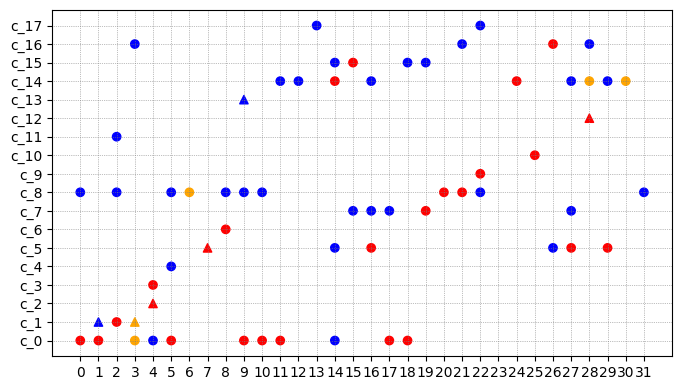

In [ ]:
x = df['id_frases']
y = df['id_conceptos']

colores = {'N': 'white', 'T': 'red', 'R': 'blue', 'B': 'orange', 'M': 'gray'}
marcadores = {'normal': 'o', 'fuente': '^'}

# Making the plot size depend on the number of sentences and concepts
fig, ax = plt.subplots(figsize=(len(list(range(n_oraciones)))/4, len(list(range(n_conceptos)))/4))
columnas = ['c_' + str(numero) for numero in range(n_conceptos)]

plt.xticks(list(range(n_oraciones)), list(range(n_oraciones)))
plt.yticks(list(range(n_conceptos)), columnas)
plt.rc('grid', linestyle=":", linewidth='0.5', color='gray')
plt.grid(True)

for tipo_simbolo, marcador in marcadores.items():
    mask = (df['t_r_menciones'] != 'N') & (df['simbolo'] == tipo_simbolo)
    ax.scatter(
        df.loc[mask, 'id_frases'],
        df.loc[mask, 'id_conceptos'],
        c=df.loc[mask, 't_r_menciones'].map(colores),
        marker=marcador
    )

plt.plot()

In [ ]:
# Esta celda sustituye al bloque antiguo que reconstruía conceptos_str
# asumiendo que las claves de conceptos_dict eran índices numéricos.
# Ahora conceptos_dict usa letras ('A', 'B', 'F'...), así que esa lógica fallaba.

df_debug = df.copy()
df_debug.loc[df_debug['t_r_menciones'] == 'N', 'id_conceptos'] = np.nan

print('Filas totales:', len(df_debug))
print('Conceptos:', n_conceptos, 'Oraciones:', n_oraciones)
print(df_debug[['id_frases', 'id_conceptos', 'str_conceptos', 't_r_menciones', 'str_menciones', 'simbolo', 'str_fuente']].head(15))


Filas totales: 576
Conceptos: 18 Oraciones: 32
    id_frases  id_conceptos                             str_conceptos  \
0           0           0.0                                   El euro   
1           0           NaN                                  insistió   
2           0           NaN   el ministro austriaco, Rudolf Edlinger,   
3           0           NaN                                el momento   
4           0           NaN  la grave crisis financiera internacional   
5           0           NaN                                  Alemania   
6           0           NaN                                  Portugal   
7           0           NaN                             la diferencia   
8           0           8.0                       nuestros ciudadanos   
9           0           NaN                         Tal circunstancia   
10          0           NaN           Las circunstancias de cada país   
11          0           NaN        el programa de estabilidad español   
12  

In [ ]:
df.str_frases = df.str_frases.str.wrap(30)
df.str_frases = df.str_frases.apply(lambda x: x.replace('\n', '<br>'))

In [ ]:
import plotly.express as px

df_plot = df[df['t_r_menciones'] != 'N'].copy()

fig = px.scatter(
    df_plot,
    x="id_frases",
    y="id_conceptos",
    color="t_r_menciones",
    symbol="simbolo",
    color_discrete_map={'T': 'red', 'R': 'blue', 'B': 'orange', 'M': 'gray'},
    symbol_map={'normal': 'circle', 'fuente': 'triangle-up'},
    hover_name="str_frases",
    hover_data={
        'id_frases': False,
        'str_frases': False,
        'id_conceptos': False,
        't_r_menciones': False,
        'str_conceptos': True,
        'str_menciones': True,
        # 'str_fuente': True,
        'simbolo': False,
        'es_fuente': False,
        'cadena_fuente': False
    }
)

fig.update_xaxes(showspikes=True, spikecolor="black", spikesnap="cursor", spikethickness=1.5, spikemode="across")
fig.update_yaxes(showspikes=True, spikecolor="black", spikesnap="cursor", spikethickness=1.5, spikemode="across")
fig.update_layout(spikedistance=100, hoverdistance=10)

fig.update_layout(
    hoverlabel=dict(
        bgcolor="white",
        font_size=14
    ),
    plot_bgcolor='rgb(230, 230, 230)',
    xaxis=dict(
        tickvals=sorted(df['id_frases'].unique()),
        tickformat=',d',
        title='Oraciones',
        fixedrange=True,
        hoverformat=None
    ),
    yaxis=dict(
        tickformat=',d',
        tickvals=sorted(df['id_conceptos'].unique()),
        ticktext=[conceptos_dict[letra] if conceptos_dict[letra] is not None else letra for letra in conceptos_orden],
        title='Conceptos',
        fixedrange=True,
        hoverformat=None
    ),
    showlegend=False
)

fig.show()